<h1> Programming for Physics <br> Lecture 15: Planetary Motion and Three Body Problem </h1>
<a target="_blank" href="https://colab.research.google.com/github/slxuphys/tamu_phys_150/blob/master/2026/lecture-15-2D-motion.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" style="background-color: white;"/>
</a>


__important__

In order to run this notebook, you need to have the `physics` module file that we made in previous lectures. You can download it from [here](./physics.py).

If you are running this notebook in Google Colab, you can upload the `physics.py` file by clicking the folder icon on the left sidebar, then clicking the upload icon.

If you are running this notebook in VSCode, make sure the `physics.py` file is in the same folder as this notebook. If you are not sure where this notebook is located, you can click its tab and select "Reveal in File Explorer".  

# Recap


## motion in 1D

###  constant velocity

<img src='../gallery/motion_constant_v.png' style='height:300px; background-color: white;' height=300>

---

### constant acceleration

<img src='../gallery/motion_constant_a.png' style='height:300px; background-color: white;' height=300>

---

### varying acceleration

<div style='display:flex;align-items:center'>

<img src='../gallery/hooke.png' style='height:300px; background-color: white;' height=300>
<div>

__Hooke's Law__
The force (F) needed to extend or compress a spring by some distance (x) scales linearly with respect to that distance.

$$ 
F = - k x
$$ 

Then from the Newton's second law, we get the acceleration,
$$
a = \frac{F}{m} = -\frac{k}{m} x
$$

</div>
</div>

## simulate the motion based on iteration (Euler method)

> __The key idea for simulating motion using programming is to break down the continuous motion into discrete time steps with small time increment $\Delta t$. This is also the idea behind calculus.__

In other words, computer simulates motion __step by step__. The simulation becomes more accurate but also more costly as the number of step increases.

With the initial condition and the update rule, one can predict the motion for arbitrarily long time.

To make the notation consistent with motion in higher dimensions, let us now use $r$ instead of $x$ for the position.

\begin{equation}
\color{red}{a_{n} = f_a(r_{n}, v_{n}, t_{n}) }
\end{equation}


\begin{equation}
\begin{aligned}
t_{n+1} &= t_{n} + \Delta t \\
v_{n+1} &= v_{n} + a_n \Delta t\\
r_{n+1} &= r_{n} + v_{n+1} \Delta t \\
\end{aligned}
\end{equation}

- simplest discrete method to simulate continuous motion. 

- $f_a (r, v, t)$ return the acceleration based the position, velocity and time.
    - motion with constant velocity: $f_a(r,v,t)=0$
    - motion with constant acceleration $a$: $f_a(r,v,t) = a$
    - spring-mass motion: $f_a(r,v,t) = -\frac{k}{m} r$
    - ...

- Once, the initial conditions ($x_0$, $v_0$) are given, we can obtain the position and velocity iteratively.

- __Not exact__. only accurate when $\Delta t \rightarrow 0$
    
    In practice, we need to make sure the result does not change as we increase `num_step` while fixing `t_max`.
    

- not the only way; other methods (more complicated) with better precision are available. You will learn more in computational physics.


## Ball Class and Motion function

In [3]:
import numpy as np 
import matplotlib.pyplot as plt
import physics as phys

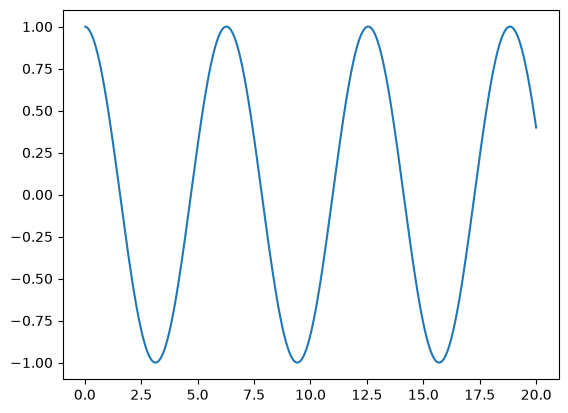

In [4]:
b =phys.Ball(x=1, v=0)
phys.motion(t_max = 20, num_step = 1000, ball = b, f_a = lambda x, v: -x)
plt.plot(b.time_list, b.pos_list)

# Motion in Higher Dimensions

## Euler method

\begin{equation}
\color{red}{\vec{a}_{n}= \vec{f}_a(\vec{r}_{n}, \vec{v}_{n}, t_{n}) }
\end{equation}

\begin{equation}
\begin{aligned}
t_{n+1} &= t_{n} + \Delta t \\
\vec{v}_{n+1} &= \vec{v}_{n} + \vec{a}_n \Delta t\\
\vec{r}_{n+1} &= \vec{r}_{n} + \vec{v}_{n+1} \Delta t \\
\end{aligned}
\end{equation}

- The position, velocity and accelerations are now vectors, for instance $\vec r = (x, y, z)$, $\vec v = (v_x, v_y, v_z)$ and $\vec a = (a_x, a_y, a_z)$. The function $\vec f_a$ also returns a vector as the acceleration.






## Summary of steps

1. Specify the initial position and velocity of the ball. (Using Ball class)
2. Specify the acceleration functions and use it as the argument of the motion function.
3. Iterate the Euler method. Consider the boundary if there is one.
4. Record the positions at each iteration.
5. Visualization - Plots and animations

## Example: Projectile Motion
Simulate the projectile motion of a ball with the same initial speed $v$ but different initial launching angles $\theta$.

<img src='../gallery/projectile.png' style='height:400px; background-color: white;' height=400>


- step 1: determine the initial condition:
$$
\vec r_0 = (0 ,0)
$$

$$
\vec v_0 = (v\cos \theta, v\sin \theta)
$$

- step 2: determine the acceleration. Projectile motion is a motion with constant acceleration. The only acceleration here is from the gravity in the vertical direction.

$$
\vec a = (0, -g)
$$

For a fixed initial speed $|v|$, what is the optimal launching angle $\theta$ to achieve the maximum horizontal range?

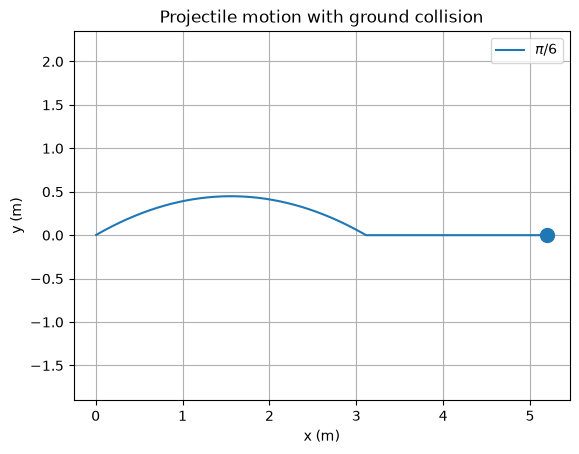

In [9]:
v = 6
theta = np.pi/6 # (30 degree)
t_max = 1
num_step = 1000
dt = t_max/num_step
b = phys.Ball(x=(0, 0), v = (v*np.cos(theta), v*np.sin(theta)))

for i in range(num_step):
    b.a=np.array((0, -10))
    b.move(dt)
    if b.x[1]<0: # when the ball hits the ground
        b.v[1] = 0
        b.x[1] = 0
    b.record()

b.pos_list = np.array(b.pos_list) # unzip the list of tuples into two lists
b.pos_x, b.pos_y = b.pos_list[:,0], b.pos_list[:,1]
#plt.plot return a list of line objects being plotted. Here only a singe line is plotted
#so we use list index [0] to get the line object and assign it to the variable b's attribute for later reference.
b.trajectory, = plt.plot(b.pos_x, b.pos_y, label=r'$\pi/6$')
plt.legend() #show the legend, the labels are corresponding to the label argument in the plt function
b.shape = plt.plot(b.pos_x[-1], b.pos_y[-1], 'o', markersize=10, color = b.trajectory.get_color()) # create a circle at the final position with the same color as the trajectory
ax = plt.gca() # get current axis
ax.axis('equal') # set equal scaling for x and y axis
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Projectile motion with ground collision')
plt.grid()


Now let balls with different launching angles race to the ground!

### wrap the code into a `projectile_motion` function

In [10]:
def projectile_motion(t_max, num_step, v, theta):
    b = phys.Ball(x=(0, 0), v = (v*np.cos(theta), v*np.sin(theta)))
    dt = t_max/num_step
    for i in range(num_step):
        b.a = np.array((0, -10)) # set the acceleration due to gravity
        b.move(dt)
        if b.x[1]<0:
            b.v[1] = 0
            b.x[1] = 0
        b.record()
    #b.max_step = len(b.pos_list)
    b.pos_list = np.array(b.pos_list) # convert the list of positions to a numpy array
    b.pos_x, b.pos_y = b.pos_list[:,0], b.pos_list[:,1] # extract x and y positions
    return b #return the ball object for later reference
    


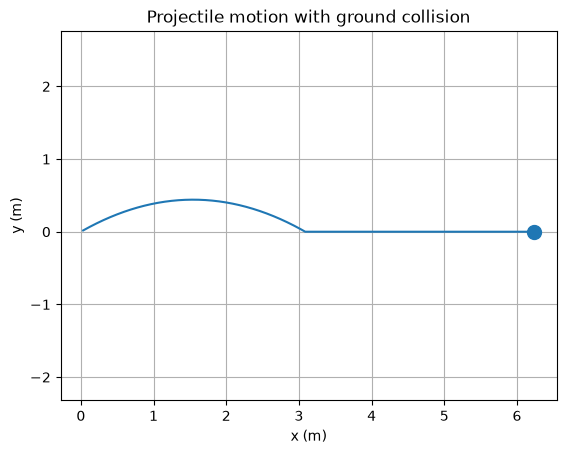

In [11]:
b = projectile_motion(t_max =1.2 , num_step =200, v=6, theta = np.pi/6)
b.trajectory= plt.plot(b.pos_x, b.pos_y, label = r'$\pi/6$')[0] # plot returns a list of line objects, we take the first one, which corresponds to the trajectory line
b.shape= plt.plot(b.pos_x[-1], b.pos_y[-1], 'o', markersize=10, color = b.trajectory.get_color())[0]

ax = plt.gca() # get current axis
ax.axis('equal') # set equal scaling for x and y axis
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Projectile motion with ground collision')
plt.grid()

### different launch angles

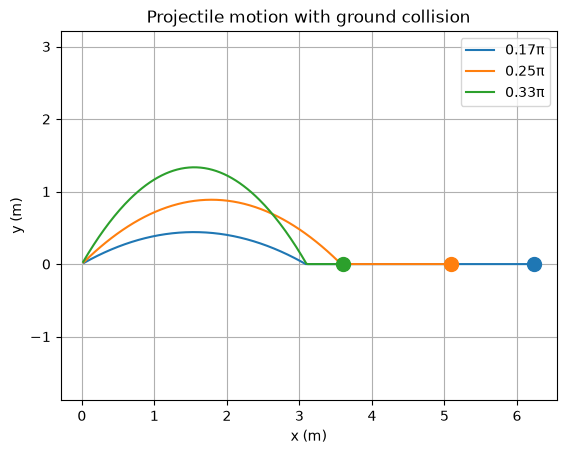

In [16]:
ball_list = [] #create an empty list to store the ball objects for different launch angles
theta_list = [np.pi/6, np.pi/4, np.pi/3] #list of launch angles to simulate

for theta in theta_list:
    b = projectile_motion(t_max =1.2 , num_step =200, v=6, theta = theta)
    b.trajectory = plt.plot(b.pos_x, b.pos_y, label = f'{theta/np.pi:.2f}π')[0] #plot the trajectory and store the line object in the ball object
    b.shape = plt.plot(b.pos_x[-1], b.pos_y[-1], 'o', markersize=10, color = b.trajectory.get_color())[0]
    ball_list.append(b) #store the ball object in the list for later reference

plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Projectile motion with ground collision')
plt.axis('equal')
plt.legend()
plt.grid()
fig = plt.gcf() # get the current figure object


### update the figure in place

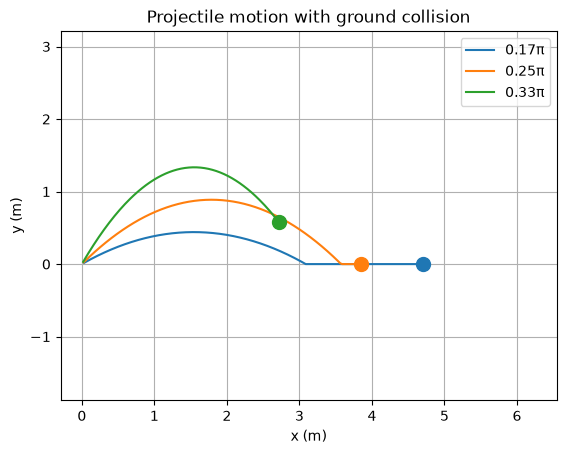

In [18]:
step = 150

for b in ball_list:
    b.trajectory.set_data(b.pos_x[:step], b.pos_y[:step]) #update the line
    b.shape.set_data([b.pos_x[step]], [b.pos_y[step]]) #update the marker position
fig  



### Animation



In [19]:
def draw_frame(frame_index):
    step = frame_index 
    for b in ball_list:
        b.trajectory.set_data(b.pos_x[:step], b.pos_y[:step]) #update the line
        b.shape.set_data([b.pos_x[step]], [b.pos_y[step]]) #update the marker position

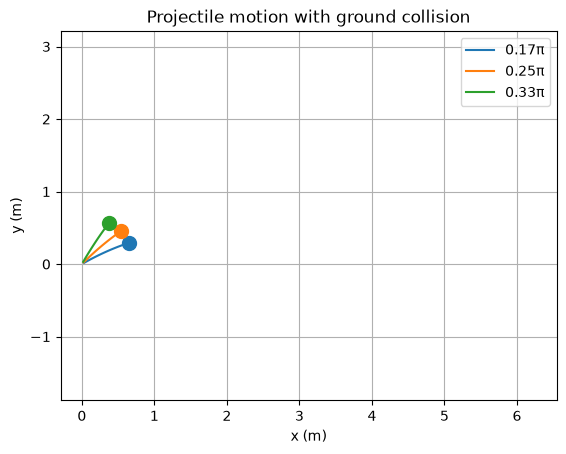

In [20]:
draw_frame(frame_index=20)
fig

In [21]:
import IPython
import matplotlib.animation as animation
anim = animation.FuncAnimation(fig, draw_frame, frames=200, interval=20)
IPython.display.HTML(anim.to_jshtml())

---

## Planetary motion
<img src='../gallery/solar-system-motion.png' alt='Solar system illustration' style='width:800px; max-width:100%; background-color: white;'>

### Central Force Problem

The force acting on the object is directed along the line joining the object and the origin.

The strength of the force only depends on the distance. Many forces in our universe appear as central forces

For example, the gravitational force between Sun and Earth, and the electric force between two charges.


<img src='../gallery/central_force.png' style='height:600px; background-color: white;' height=600>


### Euler Method for center force problem

\begin{equation}
\color{red}{\vec{a}_{n} =\frac{1}{m} \frac{f(r)}{r}\vec r}
\end{equation}

\begin{equation}
\begin{aligned}
t_{n+1} &= t_{n} + \Delta t \\
\vec{v}_{n+1} &= \vec{v}_{n} + \vec{a}_n \Delta t\\
\vec{r}_{n+1} &= \vec{r}_{n} + \vec{v}_{n+1} \Delta t \\
\end{aligned}
\end{equation}

For a vector $\vec r$ in the form of a numpy array, we can calculate its norm (length) $r$ using np.linalg.norm()

### Kepler Problem

The magnitude of the force is proportional to the inverse squared distance

- Gravity Force

- Coulomb Force

<img src='../gallery/kepler_problem.png' style='height:500px; background-color: white;'  height=500>


Now let us simulate the motion of a planet orbiting around a star under the influence of gravitational force and observe where the star is located in the orbit.

<img src='../gallery/planet-position-velocity.svg' alt='Position vector from the star at the origin to the planet, and an upward velocity vector at the planet.' style='width:760px; max-width:100%; background-color:white;'>

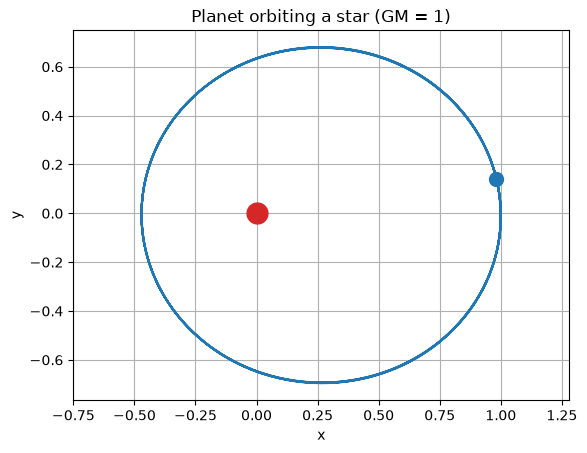

In [22]:
planet = phys.Ball(x=(1, 0), v=(0, 0.8))
phys.motion(t_max=20, num_step=1000, ball=planet,
            f_a=lambda r, v: -r / np.linalg.norm(r)**3)

# Convert the recorded positions to an array and extract its columns.
planet.pos_list = np.array(planet.pos_list)
planet.pos_x = planet.pos_list[:, 0]
planet.pos_y = planet.pos_list[:, 1]

fig, ax = plt.subplots()
planet.trajectory = plt.plot(planet.pos_x, planet.pos_y)[0]
planet.shape = plt.plot(planet.pos_x[-1], planet.pos_y[-1], 'o',
                        markersize=10, color=planet.trajectory.get_color())[0]
star = phys.Ball(x=(0, 0), v=(0, 0))
star.shape = plt.plot(0, 0, 'o', markersize=15, color='tab:red')[0]

plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Planet orbiting a star (GM = 1)')
plt.grid()


In [23]:
def draw_frame(frame_index):
    step = frame_index
    # Include the current point so the trajectory ends at the planet.
    planet.trajectory.set_data(planet.pos_x[:step + 1], planet.pos_y[:step + 1])
    planet.shape.set_data([planet.pos_x[step]], [planet.pos_y[step]])


In [24]:
# Display every fifth recorded position, including the final position.
frame_steps = list(range(0, len(planet.pos_list), 5))
if frame_steps[-1] != len(planet.pos_list) - 1:
    frame_steps.append(len(planet.pos_list) - 1)

anim = animation.FuncAnimation(fig, draw_frame, frames=frame_steps, interval=20)
IPython.display.HTML(anim.to_jshtml())


### Discussion

What if the gravity force takes another form, for instance $f(r) = -\frac{k}{r^{2.5}}$ instead of $- \frac{k}{r^2}$? Is the gravity force in our universe special?

$$
\vec F = - \frac{k}{r^{2.5}}\frac{\vec r}{r} ?
$$

---

## Few body problems

### Two body problem




Two stars attract each other through gravity force.

![image](https://upload.wikimedia.org/wikipedia/commons/thumb/f/f5/NewAlbireo.jpg/330px-NewAlbireo.jpg)

Albireo A and B


__Newton's third law__:  for every action (force) in nature there is an equal and opposite reaction. If object A exerts a force on object B, object B also exerts an equal and opposite force on object A.

<img src='../gallery/two_body_force.png' style='height:500px; background-color: white;' height=500>

\begin{equation}
\vec a_1  = -\frac{k}{m_1}\frac{\vec r_1 - \vec r_2}{\Delta r^3}, \quad \vec a_2  = -\frac{k}{m_2}\frac{\vec r_2 - \vec r_1}{\Delta r^3}
\end{equation}

In [25]:
def kepler_two_star(t_max, num_step, star1, star2):
    # assuming same mass for both stars and k=1
    dt = t_max/num_step
    for i in range(num_step):
        dr = np.linalg.norm(star1.x - star2.x) #calculate distance between the two stars
        star1.a = -(star1.x - star2.x)/dr**3
        star2.a = -(star2.x - star1.x)/dr**3 # or star2.a = -star1.a from newton's third law
        star1.move(dt)
        star2.move(dt)
        star1.record()
        star2.record()

(np.float64(-0.5500028639213835),
 np.float64(0.5500028639213835),
 np.float64(-0.41796359252619775),
 np.float64(0.41796359252619775))

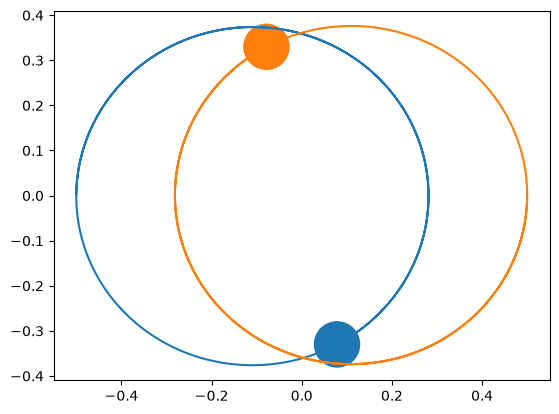

In [26]:
s1 = phys.Ball(x=(-0.5,0), v=(0, 0.6))
s2 = phys.Ball(x=(0.5,0), v=(0, -0.6))
kepler_two_star(t_max=5, num_step=1000, star1=s1, star2=s2)
s1.pos_x, s1.pos_y = zip(*s1.pos_list)
s2.pos_x, s2.pos_y = zip(*s2.pos_list)
s1.shape = plt.Circle(s1.pos_list[-1], radius=0.05, color='tab:blue')
s2.shape = plt.Circle(s2.pos_list[-1], radius=0.05, color='tab:orange')


fig, ax = plt.subplots()
plt.plot(s1.pos_x, s1.pos_y)
plt.plot(s2.pos_x, s2.pos_y)
ax.add_patch(s1.shape)
ax.add_patch(s2.shape)

plt.axis('equal')



In [27]:
def draw_frame(frame_index):
    step = 5*frame_index
    if step>=len(s1.pos_list): # avoid index out of range
        return
    s1.shape.set_center((s1.pos_x[step], s1.pos_y[step]))
    s2.shape.set_center((s2.pos_x[step], s2.pos_y[step]))

In [28]:
anim = animation.FuncAnimation(fig, draw_frame, frames=200, interval=20)
IPython.display.HTML(anim.to_jshtml())

---

## From two-body to N-body
<img src='../gallery/many_body_force.png' style='height:500px; background-color: white;' height=500>

Total force on the ith ball
$$
\vec F_i = -\sum_{j, j\neq i} \frac{k}{\Delta r_{ij}^3} (\vec r_i -\vec r_j)
$$
Total acceleration of the ith ball
$$
\vec a_i = -\frac{1}{m_i}\sum_{j, j\neq i} \frac{k}{\Delta r_{ij}^3} (\vec r_i -\vec r_j)
$$


In [29]:
def kepler_many_star(t_max, num_step, star_list):
    dt = t_max/num_step
    for i in range(num_step):
        for si in star_list:
            si.a=(0,0) #reset acceleration to zero before calculating net force
            for sj in star_list:
                if si is sj: #si and sj are the same star, no self attraction 
                    continue
                dr = np.linalg.norm(si.x - sj.x)
                si.a = si.a + (-1)*(si.x - sj.x)/dr**3
        
        for s in star_list:
            s.move(dt)
            s.record()

### three body problem

When three stars dance in mutual gravity, their motions become chaotic—an eternal struggle of attraction and imbalance.

On a distant world bathed in the light of three suns, life once thrived. But as the stars drifted apart, their skies dimmed and their world began to die. Now, an alien civilization, desperate to survive, turns its gaze toward the Solar System—a lonely realm of one sun, stable and full of promise.


<img src='https://m.media-amazon.com/images/M/MV5BMDdkYWZiZWYtMzA0Yi00NzNlLThkODktY2Q3N2NjN2ExZmMwXkEyXkFqcGc@._V1_.jpg' style='height:400px; background-color: white;' height=400>

(np.float64(-0.5499889891770833),
 np.float64(0.5499889804965278),
 np.float64(-0.27302639546669877),
 np.float64(0.4163539554207002))

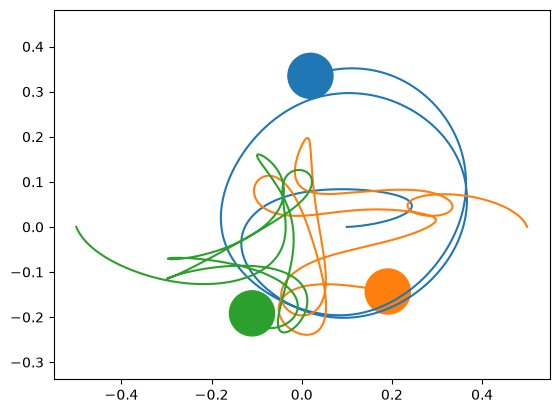

In [30]:
s1 = phys.Ball(x=(0.1,0.0),v=(0.0,-0))
s2 = phys.Ball(x=(0.5,0), v=(-0.2,0.5))
s3 = phys.Ball(x=(-0.5,0), v=(0.2,-0.5))
slist= (s1, s2, s3)
kepler_many_star(t_max=2, num_step=40000, star_list=slist)

fig, ax = plt.subplots()
for s in slist:
    s.pos_x, s.pos_y = zip(*s.pos_list)
    s.trajectory = plt.plot(s.pos_x, s.pos_y)[0] # get the line object being plotted

    s.shape = plt.Circle(s.pos_list[-1], radius=0.05, color = s.trajectory.get_color())
    ax.add_patch(s.shape)

ax.axis('equal')

In [31]:
def draw_frame(frame_index):
    step = 200*frame_index
    if step>=len(s1.pos_list): # avoid index out of range
        return
    for s in slist:
        s.shape.set_center(s.pos_list[step])

anim = animation.FuncAnimation(fig, draw_frame, frames=200, interval=20)
IPython.display.HTML(anim.to_jshtml())

Now try a different initial condition

(np.float64(-1.2045691198063304),
 np.float64(1.1900007902192578),
 np.float64(-0.4127985090891491),
 np.float64(0.39534191774280447))

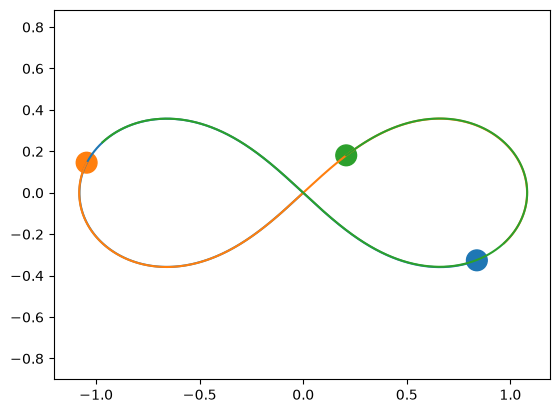

In [32]:
s1 = phys.Ball(x=(0.0,0.0),v=(-0.93240737,-0.86473146))
s2 = phys.Ball(x=(0.97000436,-0.24308753), v=(0.93240737/2,0.86473146/2))
s3 = phys.Ball(x=(-0.97000436,0.24308753), v=(0.93240737/2,0.86473146/2))
slist= (s1, s2, s3)
kepler_many_star(t_max=4, num_step=4000, star_list=slist)
fig, ax = plt.subplots()
for s in slist:
    s.pos_x, s.pos_y = zip(*s.pos_list)
    s.trajectory = plt.plot(s.pos_x, s.pos_y)[0] # get the line object being plotted

    s.shape = plt.Circle(s.pos_list[-1], radius=0.05, color = s.trajectory.get_color())
    ax.add_patch(s.shape)

ax.axis('equal')

In [33]:
def draw_frame(frame_index):
    step = 20*frame_index
    for s in slist:
        s.shape.set_center((s.pos_x[step], s.pos_y[step]))

anim = animation.FuncAnimation(fig, draw_frame, frames=200, interval=20)
IPython.display.HTML(anim.to_jshtml())


Now it's your turn to try the following initial conditions!

initial $\vec x$

(0.3361300950,0.0000000000)

(0.7699893804,0.0000000000)

(-1.1061194753,0.0000000000)

initial $\vec v$

(0.0000000000,1.5324315370)

(0.0000000000,-0.6287350978)

(0.0000000000,-0.9036964391)

With fine tuned initial positions and velocities, the three stars can move in periodic orbitals, though not stable.


<img src='https://upload.wikimedia.org/wikipedia/commons/5/5a/5_4_800_36_downscaled.gif' style="background-color: white;">

By <a href="//commons.wikimedia.org/w/index.php?title=User:Perossello&amp;action=edit&amp;redlink=1" class="new" title="User:Perossello (page does not exist)">Perosello</a> - <a rel="nofollow" class="external text" href="https://x.com/PeRossello/status/1670803430544142338?s=20">Uploaded by Author</a>, <a href="https://creativecommons.org/licenses/by-sa/4.0" title="Creative Commons Attribution-Share Alike 4.0">CC BY-SA 4.0</a>, <a href="https://commons.wikimedia.org/w/index.php?curid=133294338">Link</a>

Also see: https://staff.aist.go.jp/k.koide/workspace/threebody/index.html